## Project Overview

Analyzing retail sales data using Python to identify sales trends, product performance, and business insights.

**Tools:** Python, NumPy, Pandas, Matplotlib, Seaborn

**Dataset:** Sample Superstore

### Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Load Dataset

In [3]:
df = pd.read_csv("SampleSuperstore.csv")

### Data Exploration

In [4]:
df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [6]:
df.shape

(9994, 13)

In [7]:
df.columns

Index(['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code',
       'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Ship Mode     9994 non-null   str    
 1   Segment       9994 non-null   str    
 2   Country       9994 non-null   str    
 3   City          9994 non-null   str    
 4   State         9994 non-null   str    
 5   Postal Code   9994 non-null   int64  
 6   Region        9994 non-null   str    
 7   Category      9994 non-null   str    
 8   Sub-Category  9994 non-null   str    
 9   Sales         9994 non-null   float64
 10  Quantity      9994 non-null   int64  
 11  Discount      9994 non-null   float64
 12  Profit        9994 non-null   float64
dtypes: float64(3), int64(2), str(8)
memory usage: 1.7 MB


### Data Cleaning

In [10]:
df.isna().sum()

Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(17)

In [14]:
df.drop_duplicates(inplace = True)

In [16]:
df.duplicated().sum()

np.int64(0)

### Statistical Analysis

In [17]:
df.describe()

,Postal Code,Sales,Quantity,Discount,Profit
count,9977.000000,9977.000000,9977.000000,9977.000000,9977.00000
mean,55154.964117,230.148902,3.790719,0.156278,28.69013
std,32058.266816,623.721409,2.226657,0.206455,234.45784
min,1040.000000,0.444000,1.000000,0.000000,-6599.97800
25%,23223.000000,17.300000,2.000000,0.000000,1.72620
50%,55901.000000,54.816000,3.000000,0.200000,8.67100
75%,90008.000000,209.970000,5.000000,0.200000,29.37200
max,99301.000000,22638.480000,14.000000,0.800000,8399.97600


### Categorical Analysis

In [18]:
df.nunique()

Ship Mode          4
Segment            3
Country            1
City             531
State             49
Postal Code      631
Region             4
Category           3
Sub-Category      17
Sales           5825
Quantity          14
Discount          12
Profit          7287
dtype: int64

In [20]:
df['Category'].unique()

<ArrowStringArray>
['Furniture', 'Office Supplies', 'Technology']
Length: 3, dtype: str

In [22]:
df['Category'].value_counts()

Category
Office Supplies    6012
Furniture          2118
Technology         1847
Name: count, dtype: int64

### Sales Analysis

In [23]:
# Now let's calculate total sales for each category.

df.groupby('Category')['Sales'].sum().sort_values(ascending=False)

Category
Technology         836154.0330
Furniture          741306.3133
Office Supplies    718735.2440
Name: Sales, dtype: float64

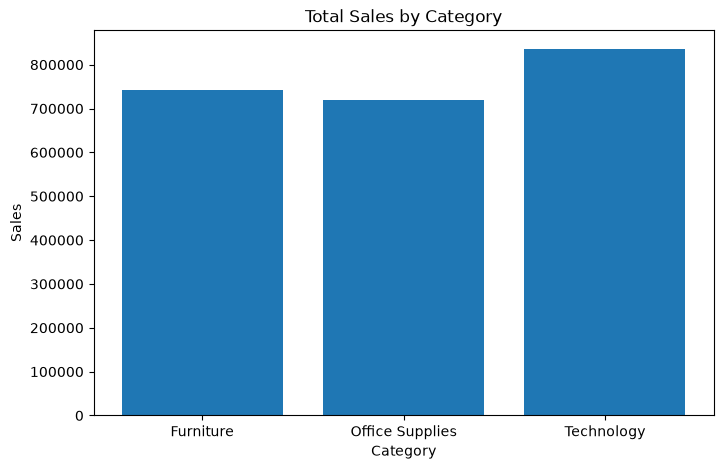

In [26]:
# Visualize Sales by Category

sales_by_category = df.groupby('Category')['Sales'].sum()

plt.figure(figsize = (8,5))

plt.bar(sales_by_category.index ,sales_by_category.values )

plt.xlabel('Category')
plt.ylabel('Sales')
plt.title('Total Sales by Category')

plt.show()

### Profit Analysis

In [28]:
# Calculate total profit by category

profit_by_category = df.groupby('Category')['Profit'].sum()

profit_by_category

Category
Furniture           18421.8137
Office Supplies    122364.6608
Technology         145454.9481
Name: Profit, dtype: float64

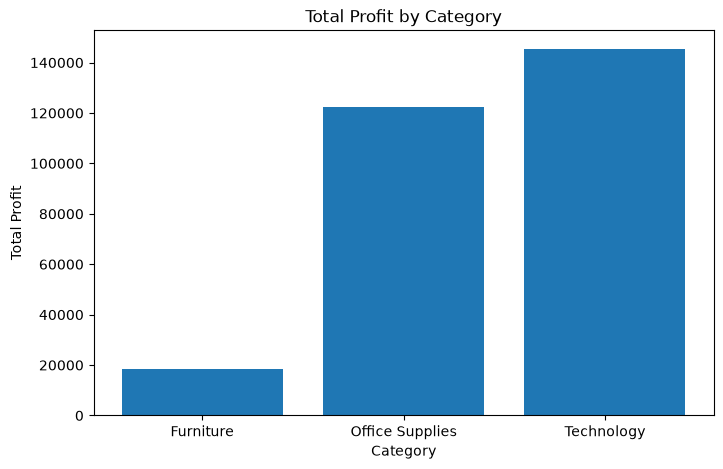

In [29]:
# Visualize Profit by Category

plt.figure(figsize=(8,5))

plt.bar(profit_by_category.index, profit_by_category.values)

plt.xlabel('Category')
plt.ylabel('Total Profit')
plt.title('Total Profit by Category')

plt.show()

In [30]:
# Calculate total sales by region

sales_by_region = df.groupby('Region')['Sales'].sum()

sales_by_region

Region
Central    500782.8528
East       678435.1960
South      391721.9050
West       725255.6365
Name: Sales, dtype: float64

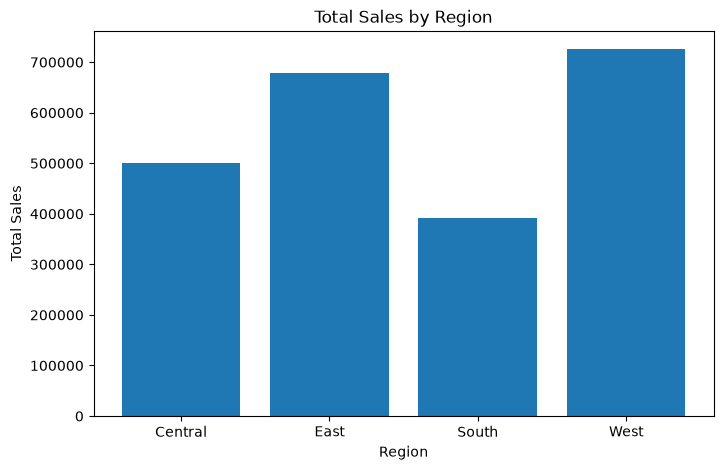

In [32]:
# Visualize Sales by Region

plt.figure(figsize=(8,5))

plt.bar(sales_by_region.index, sales_by_region.values)

plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.title('Total Sales by Region')

plt.show()

In [33]:
# Calculate total profit by region

profit_by_region = df.groupby('Region')['Profit'].sum()

profit_by_region

Region
Central     39655.8752
East        91506.3092
South       46749.4303
West       108329.8079
Name: Profit, dtype: float64

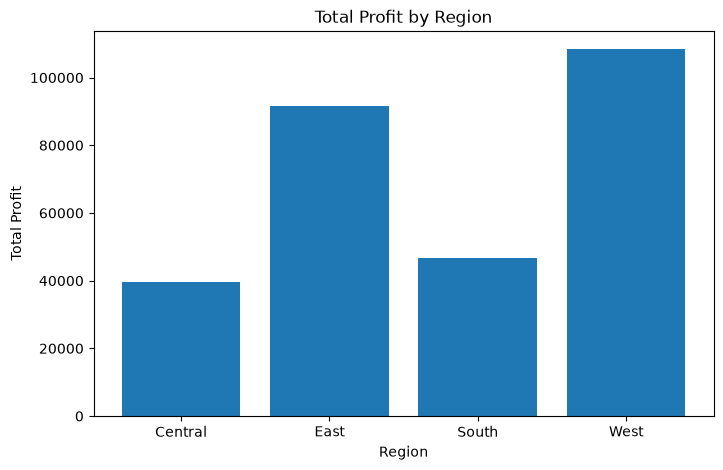

In [34]:
# Visualize Profit by Region

plt.figure(figsize=(8,5))

plt.bar(profit_by_region.index, profit_by_region.values)

plt.xlabel('Region')
plt.ylabel('Total Profit')
plt.title('Total Profit by Region')

plt.show()

In [35]:
sales_by_subcategory = df.groupby('Sub-Category')['Sales'].sum().sort_values(ascending=False)

sales_by_subcategory

Sub-Category
Phones         330007.0540
Chairs         327777.7610
Storage        223843.6080
Tables         206965.5320
Binders        203409.1690
Machines       189238.6310
Accessories    167380.3180
Copiers        149528.0300
Bookcases      114879.9963
Appliances     107532.1610
Furnishings     91683.0240
Paper           78224.1420
Supplies        46673.5380
Art             27107.0320
Envelopes       16476.4020
Labels          12444.9120
Fasteners        3024.2800
Name: Sales, dtype: float64

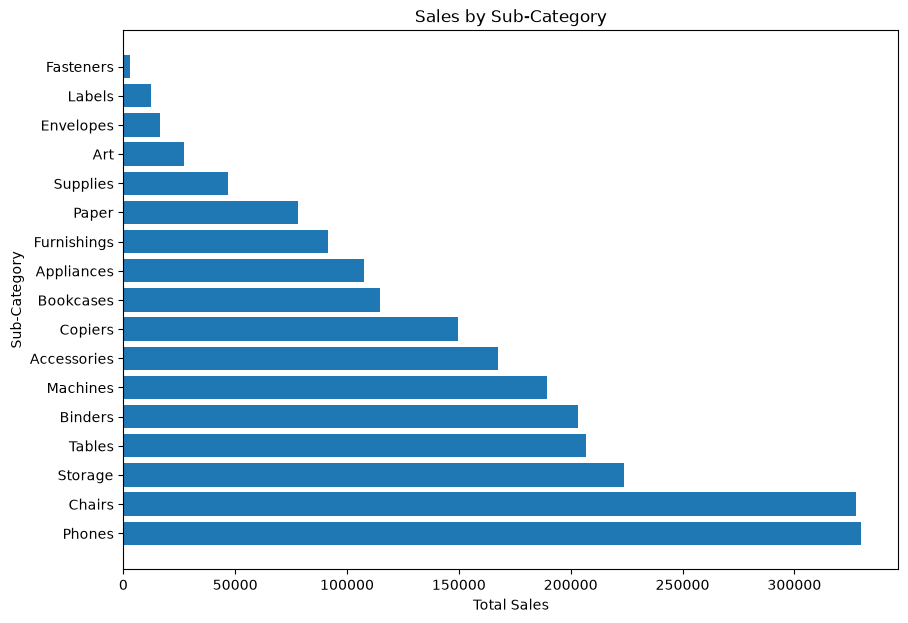

In [38]:
plt.figure(figsize=(10,7))

plt.barh(sales_by_subcategory.index, sales_by_subcategory.values)

plt.xlabel('Total Sales')
plt.ylabel('Sub-Category')
plt.title('Sales by Sub-Category')

plt.show()

In [39]:
profit_by_subcategory = df.groupby('Sub-Category')['Profit'].sum().sort_values(ascending=False)

profit_by_subcategory

Sub-Category
Copiers        55617.8249
Phones         44515.7306
Accessories    41936.6357
Paper          33944.2395
Binders        30228.0003
Chairs         26567.1278
Storage        21278.8264
Appliances     18138.0054
Furnishings    13052.7230
Envelopes       6964.1767
Art             6524.6118
Labels          5526.3820
Machines        3384.7569
Fasteners        949.5182
Supplies       -1189.0995
Bookcases      -3472.5560
Tables        -17725.4811
Name: Profit, dtype: float64

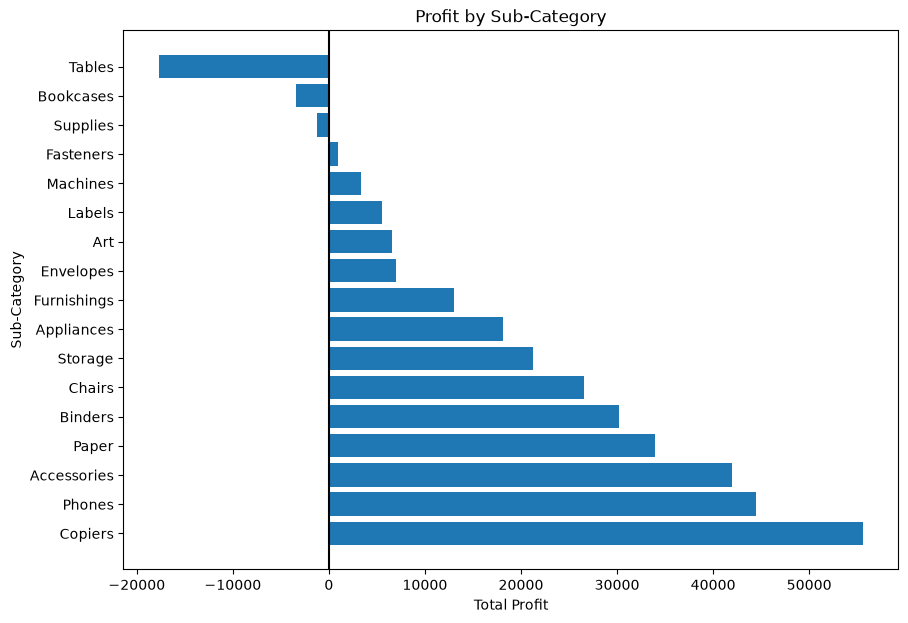

In [40]:
plt.figure(figsize=(10,7))

plt.barh(profit_by_subcategory.index, profit_by_subcategory.values)

plt.xlabel('Total Profit')
plt.ylabel('Sub-Category')
plt.title('Profit by Sub-Category')

plt.axvline(0, color='black')

plt.show()

In [41]:
sales_by_segment = df.groupby('Segment')['Sales'].sum().sort_values(ascending=False)

sales_by_segment

Segment
Consumer       1.160833e+06
Corporate      7.060701e+05
Home Office    4.292927e+05
Name: Sales, dtype: float64

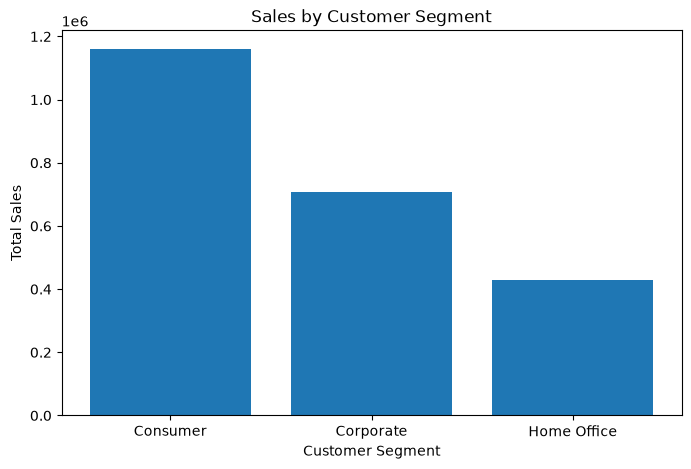

In [42]:
plt.figure(figsize=(8,5))

plt.bar(sales_by_segment.index, sales_by_segment.values)

plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')
plt.title('Sales by Customer Segment')

plt.show()

In [43]:
profit_by_segment = df.groupby('Segment')['Profit'].sum().sort_values(ascending=False)

profit_by_segment

Segment
Consumer       134007.4413
Corporate       91954.9798
Home Office     60279.0015
Name: Profit, dtype: float64

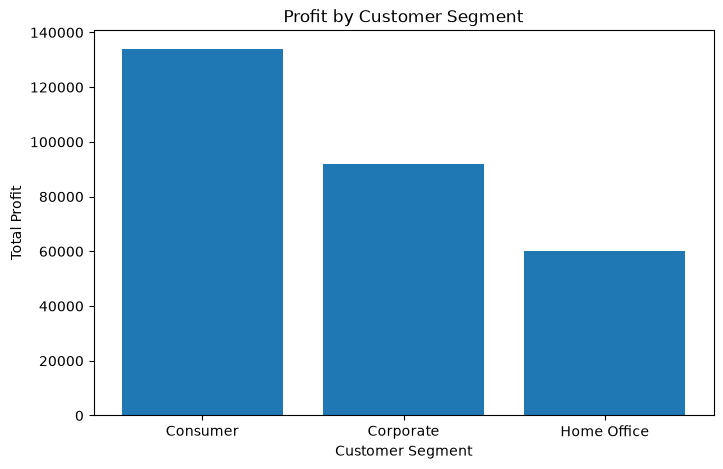

In [44]:
plt.figure(figsize=(8,5))

plt.bar(profit_by_segment.index, profit_by_segment.values)

plt.xlabel('Customer Segment')
plt.ylabel('Total Profit')
plt.title('Profit by Customer Segment')

plt.show()

In [45]:
sales_by_shipmode = df.groupby('Ship Mode')['Sales'].sum().sort_values(ascending=False)

sales_by_shipmode

Ship Mode
Standard Class    1.357316e+06
Second Class      4.591770e+05
First Class       3.513805e+05
Same Day          1.283217e+05
Name: Sales, dtype: float64

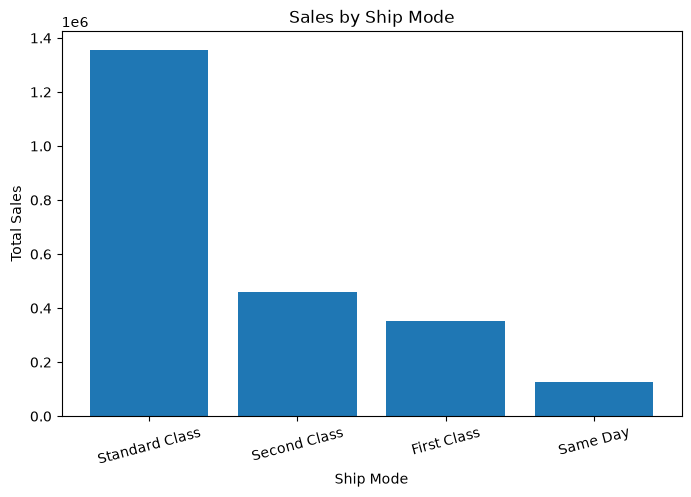

In [46]:
plt.figure(figsize=(8,5))

plt.bar(sales_by_shipmode.index, sales_by_shipmode.values)

plt.xlabel('Ship Mode')
plt.ylabel('Total Sales')
plt.title('Sales by Ship Mode')

plt.xticks(rotation=15)
plt.show()

### Discount Analysis

In [49]:
# Discount vs Profit

discount_profit = df.groupby('Discount')['Profit'].mean()

discount_profit

Discount
0.00     67.024108
0.10     96.055074
0.15     27.288298
0.20     24.721217
0.30    -45.828401
0.32    -88.560656
0.40   -111.927429
0.45   -226.646464
0.50   -310.703456
0.60    -43.077212
0.70    -95.874060
0.80   -102.116395
Name: Profit, dtype: float64

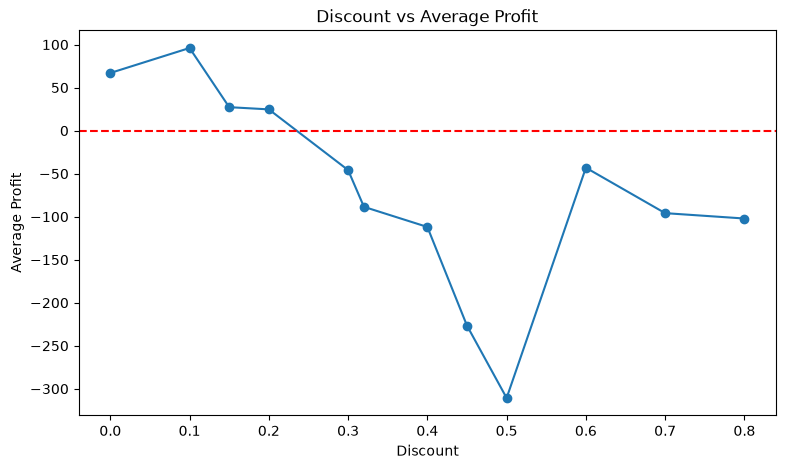

In [50]:
plt.figure(figsize=(9,5))

plt.plot(discount_profit.index, discount_profit.values, marker='o')

plt.xlabel('Discount')
plt.ylabel('Average Profit')
plt.title('Discount vs Average Profit')

plt.axhline(0, color='red', linestyle='--')

plt.show()

### Correlation Analysis

In [54]:
# Correlation Analysis

correlation = df[['Sales', 'Quantity', 'Discount', 'Profit']].corr()

correlation

,Sales,Quantity,Discount,Profit
Sales,1.000000,0.200722,-0.028311,0.479067
Quantity,0.200722,1.000000,0.008678,0.066211
Discount,-0.028311,0.008678,1.000000,-0.219662
Profit,0.479067,0.066211,-0.219662,1.000000


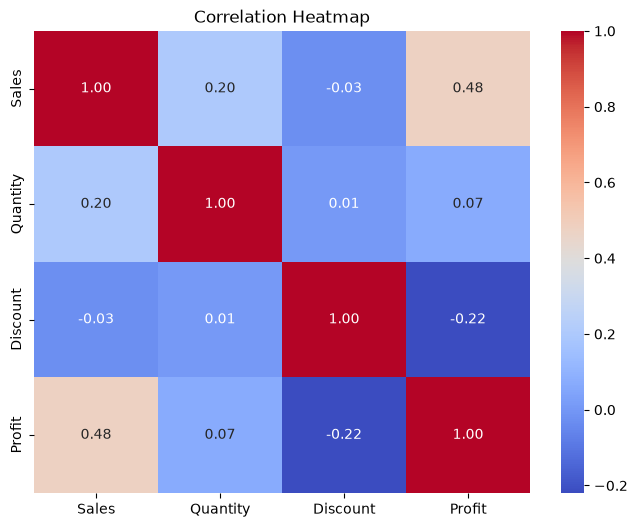

In [55]:
plt.figure(figsize=(8,6))

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')

plt.show()

### Business KPIs

In [56]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = len(df)
average_sales = df['Sales'].mean()
average_profit = df['Profit'].mean()

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Records:", total_orders)
print("Average Sales:", round(average_sales, 2))
print("Average Profit:", round(average_profit, 2))

Total Sales: 2296195.59
Total Profit: 286241.42
Total Records: 9977
Average Sales: 230.15
Average Profit: 28.69


### Sales vs Profit Comparison

In [60]:
# Sales vs Profit by Category

category_sales = df.groupby('Category')['Sales'].sum()

category_profit = df.groupby('Category')['Profit'].sum()

x = np.arange(len(category_sales))

width = 0.35

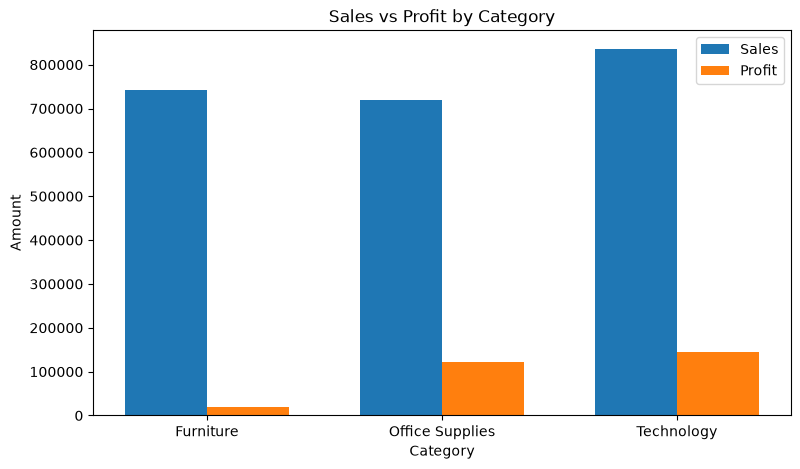

In [61]:
plt.figure(figsize=(9,5))

plt.bar(x - width/2, category_sales.values, width, label='Sales')
plt.bar(x + width/2, category_profit.values, width, label='Profit')

plt.xticks(x, category_sales.index)
plt.xlabel('Category')
plt.ylabel('Amount')
plt.title('Sales vs Profit by Category')

plt.legend()
plt.show()